# Quantum tools for nonlinear differential equations — solutions

This notebook follows the masterclass slides step by step:

| Part | Topic | Slides | Exercise (solved) |
|---|---|---|---|
| 1 | Carleman linearization: scalar ODE and viscous Burgers | 2–3 | Exercise 1 |
| 2 | Linear combination of Hamiltonian simulations (LCHS) | 4–5 | Exercise 2 |
| 3 | Block encoding by linear combination of unitaries (LCU) | 6–7 | Exercise 3 |
| 4 | Lattice Boltzmann + Carleman: Mach number and viscosity | 8–10 | Exercises 4 and 5 |
| 5 | Running $e^{-iHt}$ on spin qubit hardware with SpinPulse | SDK demo | Exercise 6 |
| 6 | Summary | 11 | – |

All exercises are filled in and every check passes. Results in Parts 1–4 match the numbers on the slides.

Everything is emulated classically with small matrices, so each step can be compared with an exact answer. **Requirements:** `numpy`, `scipy`, `matplotlib` for Parts 1–4, which run in a few seconds. Part 5 also needs SpinPulse (`pip install spin-pulse`) and takes about a minute.

In [1]:
import numpy as np
import scipy.sparse as sp
import matplotlib.pyplot as plt
from scipy.linalg import expm
from scipy.integrate import solve_ivp
from functools import reduce
from itertools import product

np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({"figure.figsize": (6.5, 4), "axes.grid": True, "grid.alpha": 0.3})
kron_all = lambda mats: reduce(np.kron, mats)


def check(cond, msg):
    print(("✓ " if cond else "✗ ") + msg)
    if not cond:
        raise AssertionError(msg)

print("Ready.")

Ready.


---
## Part 1: Carleman linearization — trade nonlinearity for dimension

Take the quadratic ODE

$$\frac{du}{dt} = a\,u + b\,u^2 .$$

Introduce $y_j = u^j$. By the chain rule,

$$\frac{dy_j}{dt} = j\,u^{j-1}\frac{du}{dt} = j a\, y_j + j b\, y_{j+1},$$

so each power couples only to the next one: an **infinite linear system**. Truncating at order $N$ gives $\dot{\mathbf y} = A_N \mathbf y$ with $A_N$ upper bidiagonal, and $y_1$ approximates $u$.

For a PDE discretized on $n$ grid points, $\dot{\mathbf u} = F_1\mathbf u + F_2(\mathbf u\otimes\mathbf u)$, the state becomes $\mathbf u, \mathbf u^{\otimes2},\dots,\mathbf u^{\otimes N}$: dimension $n + n^2 + \dots + n^N$, but only about $N\log_2 n$ qubits. Liu et al. (PNAS 2021) prove convergence when

$$R = \frac{\|u_0\|\,\|F_2\|}{|\mathrm{Re}\,\lambda_1|} < 1 .$$

**✏️ Exercise 1.** Build the $N\times N$ Carleman matrix: row $j$ has $j a$ on the diagonal and $j b$ just right of it.

In [2]:
def carleman_scalar(a, b, N):
    A = np.zeros((N, N))
    for j in range(1, N + 1):
        A[j - 1, j - 1] = j * a          # j*a*y_j
        if j < N:
            A[j - 1, j] = j * b          # j*b*y_{j+1}
    return A

✓ Carleman matrix is correct (fill in Exercise 1)


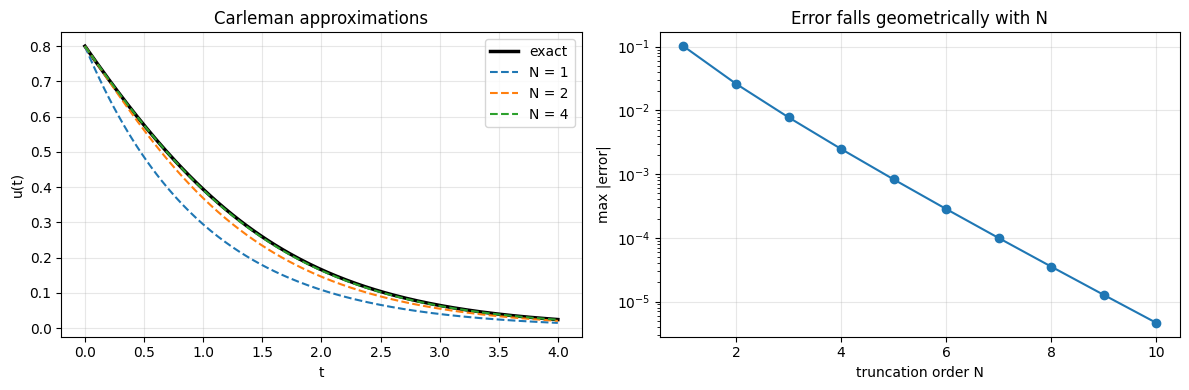

error at N = 1: 0.10,  at N = 10: 4.6e-06


In [3]:
check(np.allclose(carleman_scalar(-1, 0.5, 3), [[-1, 0.5, 0], [0, -2, 1], [0, 0, -3]]),
      "Carleman matrix is correct (fill in Exercise 1)")

a, b, u0, T = -1.0, 0.5, 0.8, 4.0
t = np.linspace(0, T, 200)
ref = solve_ivp(lambda t, u: a * u + b * u**2, (0, T), [u0], t_eval=t, rtol=1e-12, atol=1e-14).y[0]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(t, ref, "k", lw=2.5, label="exact")
Ns, errors = range(1, 11), []
for N in Ns:
    y0 = u0 ** np.arange(1, N + 1)
    uN = np.array([(expm(carleman_scalar(a, b, N) * tt) @ y0)[0] for tt in t])
    errors.append(np.max(np.abs(uN - ref)))
    if N in (1, 2, 4):
        ax[0].plot(t, uN, "--", label=f"N = {N}")
ax[0].set(xlabel="t", ylabel="u(t)", title="Carleman approximations"); ax[0].legend()
ax[1].semilogy(list(Ns), errors, "o-")
ax[1].set(xlabel="truncation order N", ylabel="max |error|", title="Error falls geometrically with N")
plt.tight_layout(); plt.show()
print(f"error at N = 1: {errors[0]:.2f},  at N = 10: {errors[-1]:.1e}")

**From ODE to PDE.** The viscous Burgers equation $\partial_t u + u\,\partial_x u = \nu\,\partial_x^2 u$ with zero boundary values, on 6 interior grid points. The Carleman matrix has blocks $A_{j,j} = \sum_k I^{\otimes(k-1)}\otimes F_1\otimes I^{\otimes(j-k)}$ and $A_{j,j+1}$ built the same way from $F_2$.

In [4]:
def burgers_operators(n, nu):
    dx = 1.0 / (n + 1)
    F1 = nu / dx**2 * (-2 * np.eye(n) + np.eye(n, k=1) + np.eye(n, k=-1))
    F2 = np.zeros((n, n * n))
    for i in range(n):                       # -(u_{i+1}^2 - u_{i-1}^2) / (4 dx)
        if i + 1 < n: F2[i, (i + 1) * (n + 1)] -= 1 / (4 * dx)
        if i > 0:     F2[i, (i - 1) * (n + 1)] += 1 / (4 * dx)
    return F1, F2


def carleman_matrix(F1, F2, N):
    n, I = F1.shape[0], np.eye(F1.shape[0])
    offs = np.concatenate([[0], np.cumsum([n**j for j in range(1, N + 1)])])
    A = np.zeros((offs[-1], offs[-1]))
    lift = lambda F, j: sum(kron_all([I] * (k - 1) + [F] + [I] * (j - k)) for k in range(1, j + 1))
    for j in range(1, N + 1):
        A[offs[j - 1]:offs[j], offs[j - 1]:offs[j]] = lift(F1, j)
        if j < N:
            A[offs[j - 1]:offs[j], offs[j]:offs[j + 1]] = lift(F2, j)
    return A


n, nu, T = 6, 0.05, 1.0
x = np.linspace(0, 1, n + 2)[1:-1]
u0_vec = 0.4 * np.sin(np.pi * x)
F1, F2 = burgers_operators(n, nu)
u_ref = solve_ivp(lambda t, u: F1 @ u + F2 @ np.kron(u, u), (0, T), u0_vec, rtol=1e-12, atol=1e-14).y[:, -1]
R = np.linalg.norm(u0_vec) * np.linalg.norm(F2, 2) / abs(np.max(np.linalg.eigvalsh(F1)))

print(f"R = {R:.1f}  (convergence is proven only for R < 1)\n")
print(f"{'N':>2} {'dimension':>10} {'qubits':>7} {'rel. error':>11}")
for N in range(1, 5):
    y0 = np.concatenate([kron_all([u0_vec] * j) for j in range(1, N + 1)])
    uN = (expm(carleman_matrix(F1, F2, N) * T) @ y0)[:n]
    print(f"{N:>2} {len(y0):>10} {int(np.ceil(np.log2(len(y0)))):>7} {np.linalg.norm(uN - u_ref) / np.linalg.norm(u_ref):>11.1e}")

R = 4.9  (convergence is proven only for R < 1)

 N  dimension  qubits  rel. error
 1          6       3     2.2e-01
 2         42       6     8.8e-02
 3        258       9     3.3e-02


 4       1554      11     1.2e-02


**Takeaways.** The dimension multiplies by $n$ per order; the qubit count grows by only about $\log_2 n$. Here $R \approx 4.9$, outside the theorem, yet the error still falls: $R<1$ is sufficient, not necessary, so worst-case bounds can overestimate the resources a given problem needs.

---
## Part 2: LCHS — non-unitary dynamics from unitaries

After linearization, $\dot{\mathbf y} = -A\mathbf y$ has the propagator $e^{-tA}$, which is **not unitary** and cannot be applied directly as a circuit. Split $A$ into two Hermitian parts,

$$A = L + iH, \qquad L = \frac{A + A^\dagger}{2}, \qquad H = \frac{A - A^\dagger}{2i}.$$

If $L \succeq 0$ (dissipative dynamics), An, Liu and Lin (PRL 2023) show

$$e^{-tA} = \int_{-\infty}^{\infty} \frac{1}{\pi(1+k^2)}\; e^{-it(kL + H)}\, dk ,$$

a weighted integral of **Hamiltonian simulations**. With $M$ quadrature nodes it becomes a sum of $M$ unitaries, implemented by LCU on $\lceil \log_2 M\rceil$ ancilla qubits.

**✏️ Exercise 2.** Write `split(A)`, which returns `L, H`. (`A.conj().T` is $A^\dagger$.)

In [5]:
def split(A):
    L = (A + A.conj().T) / 2
    H = (A - A.conj().T) / (2j)
    return L, H

✓ split(A) returns L and H (fill in Exercise 2)
✓ L and H are Hermitian
✓ A = L + iH


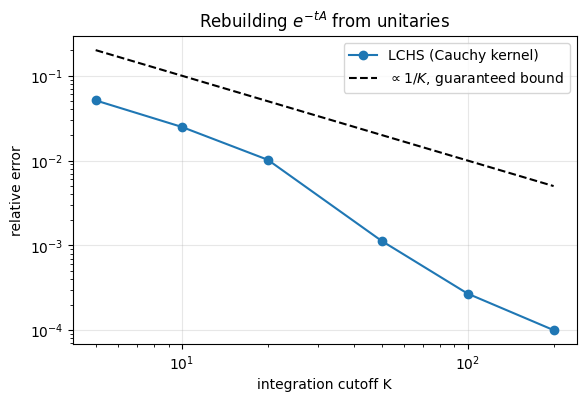

error at K = 5: 5e-02,  at K = 200: 1e-04


In [6]:
rng = np.random.default_rng(1)
d, t = 4, 1.0
M = rng.normal(size=(d, d)); K = rng.normal(size=(d, d))
A = (M @ M.T / d + 0.1 * np.eye(d)) + 1j * (K + K.T) / 2      # dissipative test matrix
L, H = split(A)
check(L is not None and H is not None, "split(A) returns L and H (fill in Exercise 2)")
check(np.allclose(L, L.conj().T) and np.allclose(H, H.conj().T), "L and H are Hermitian")
check(np.allclose(L + 1j * H, A), "A = L + iH")


def lchs(L, H, t, K_cut, M):
    h = 2 * K_cut / M                                          # midpoint rule on [-K_cut, K_cut]
    ks = -K_cut + h * (np.arange(M) + 0.5)
    return sum(h / (np.pi * (1 + k**2)) * expm(-1j * t * (k * L + H)) for k in ks)


exact = expm(-t * A)
K_vals = [5, 10, 20, 50, 100, 200]
errs = [np.linalg.norm(lchs(L, H, t, Kc, 20 * Kc) - exact, 2) / np.linalg.norm(exact, 2) for Kc in K_vals]
plt.loglog(K_vals, errs, "o-", label="LCHS (Cauchy kernel)")
plt.loglog(K_vals, 1 / np.array(K_vals), "k--", label=r"$\propto 1/K$, guaranteed bound")
plt.xlabel("integration cutoff K"); plt.ylabel("relative error")
plt.title(r"Rebuilding $e^{-tA}$ from unitaries"); plt.legend(); plt.show()
print(f"error at K = 5: {errs[0]:.0e},  at K = 200: {errs[-1]:.0e}")

**Takeaways.** Only unitary evolutions were used. The guaranteed error is $O(1/K)$ because the kernel has heavy tails; here cancellations make it fall faster, but cost estimates use the bound. A larger cutoff means longer simulation times $kt$. Improved kernels (An, Childs, Lin, 2023) decay almost exponentially.

---
## Part 3: Block encoding by LCU — a matrix inside a unitary

A unitary $U$ **block-encodes** $A$ with normalization $\alpha$ if $A/\alpha$ is its top-left block:

$$U = \begin{pmatrix} A/\alpha & \ast \\ \ast & \ast \end{pmatrix}, \qquad A = \alpha\,(\langle 0|\otimes I)\,U\,(|0\rangle\otimes I).$$

LCU builds one from $A = \sum_i c_i P_i$ (Pauli strings, signs absorbed so $c_i > 0$, $\alpha = \sum_i c_i$):

$$U = (\mathrm{PREP}^\dagger \otimes I)\;\mathrm{SELECT}\;(\mathrm{PREP} \otimes I), \qquad \mathrm{PREP}|0\rangle = \sum_i \sqrt{c_i/\alpha}\;|i\rangle, \qquad \mathrm{SELECT} = \sum_i |i\rangle\langle i| \otimes P_i .$$

Algorithms need about $\alpha t$ queries to $U$ for simulation and $\alpha\|A^{-1}\|$ for linear systems, so a small $\alpha$ matters. We encode the 1D Laplacian stencil on 4 grid points (2 qubits).

In [7]:
PAULIS = {"I": np.eye(2), "X": np.array([[0, 1], [1, 0]]),
          "Y": np.array([[0, -1j], [1j, 0]]), "Z": np.diag([1, -1])}

A_lap = 2 * np.eye(4) - np.eye(4, k=1) - np.eye(4, k=-1)
terms = []
for labels in product("IXYZ", repeat=2):
    lab = "".join(labels)
    c = np.trace(kron_all([PAULIS[l] for l in lab]).conj().T @ A_lap) / 4
    if abs(c) > 1e-12:
        terms.append((lab, c))
print(A_lap)
print("\nA =", " ".join(f"{c.real:+.1f}·{lab}" for lab, c in terms))

[[ 2. -1.  0.  0.]
 [-1.  2. -1.  0.]
 [ 0. -1.  2. -1.]
 [ 0.  0. -1.  2.]]

A = +2.0·II -1.0·IX -0.5·XX -0.5·YY


**✏️ Exercise 3.** Compute the normalization `alpha` and the amplitudes `prep_amplitudes` that PREP loads on the ancilla register.

In [8]:
coeffs = np.array([abs(c) for _, c in terms])
alpha = coeffs.sum()
prep_amplitudes = np.sqrt(coeffs / alpha)

In [9]:
check(alpha is not None and prep_amplitudes is not None, "alpha and prep_amplitudes are set (fill in Exercise 3)")
check(np.isclose(np.sum(np.abs(prep_amplitudes) ** 2), 1), "PREP amplitudes form a normalized state")

na = int(np.ceil(np.log2(len(terms))))                              # ancilla qubits
v = np.zeros(2**na); v[:len(terms)] = prep_amplitudes
Q, _ = np.linalg.qr(np.column_stack([v, np.eye(2**na)[:, 1:]]))
PREP = Q if Q[:, 0] @ v > 0 else -Q                                 # a unitary whose first column is v
SELECT = sum(np.kron(np.diag(np.eye(2**na)[i]), np.exp(1j * np.angle(c)) * kron_all([PAULIS[l] for l in lab]))
             for i, (lab, c) in enumerate(terms))
U = np.kron(PREP.conj().T, np.eye(4)) @ SELECT @ np.kron(PREP, np.eye(4))

check(np.allclose(U.conj().T @ U, np.eye(len(U))), "U is unitary")
check(np.allclose(alpha * U[:4, :4], A_lap), "alpha × top-left block of U equals A")
print(f"\nPauli terms = {len(terms)},  ancilla qubits = {na},  alpha = {alpha:.2f},  ||A||_2 = {np.linalg.norm(A_lap, 2):.2f}")

✓ alpha and prep_amplitudes are set (fill in Exercise 3)
✓ PREP amplitudes form a normalized state
✓ U is unitary
✓ alpha × top-left block of U equals A

Pauli terms = 4,  ancilla qubits = 2,  alpha = 4.00,  ||A||_2 = 3.62


**Takeaways.** The encoding is exact; the price is $\alpha \geq \|A\|_2$, here about 10% above. On larger grids a generic Pauli decomposition gets worse (the periodic 8-point Laplacian gives $\alpha = 5$), while encoding the shift operator directly as a circuit keeps $\alpha = 4$.

---
## Part 4: Lattice Boltzmann + Carleman — move the nonlinearity into a local collision

In Navier–Stokes or Burgers, the nonlinearity $u\,\partial_x u$ grows with the Reynolds number, which is where Carleman fails. The lattice Boltzmann method describes the same flow with particle populations $f_i(x,t)$:

$$f_i(x + c_i,\, t+1) = f_i - \omega\,\big(f_i - f_i^{\rm eq}(f)\big).$$

We use the D1Q3 lattice: velocities $c_i \in \{0, +1, -1\}$, weights $w_i = (2/3, 1/6, 1/6)$, $c_s^2 = 1/3$. Density and momentum are linear in $f$: $\rho = \sum_i f_i$, $J = \rho u = \sum_i c_i f_i$. With the second-order equilibrium, and $\rho \approx 1$ in the quadratic term,

$$f_i^{\rm eq} = w_i\Big(\rho + \frac{c_i J}{c_s^2} + \frac{(c_i^2 - c_s^2)\,J^2}{2 c_s^4}\Big).$$

One time step is then a quadratic map, $f \mapsto S\,(C_1 f + C_2\, f\otimes f)$:
- **streaming** $S$ is a permutation, a shift circuit on qubits;
- the **collision** is local and quadratic, with strength set by the **Mach number** $u/c_s$;
- the relaxation rate sets the viscosity, $\nu = c_s^2(1/\omega - 1/2)$.

References: Itani, Succi, *Fluids* 7, 24 (2022); Sanavio, Succi, *AVS Quantum Sci.* 6, 023802 (2024).

**✏️ Exercise 4.** Write `equilibrium(rho, u)`, which returns the vector $(f_0^{\rm eq}, f_1^{\rm eq}, f_2^{\rm eq})$ for arrays `rho` and `u` over the lattice, stacked as one vector of length $3n$ ($f_i(x)$ at index $i\,n + x$). Use $J = \rho u$.

In [10]:
c_lat = np.array([0, 1, -1])
w_lat = np.array([2 / 3, 1 / 6, 1 / 6])
cs2 = 1 / 3
Q_lat = 3

In [11]:
def equilibrium(rho, u):
    J = rho * u
    return np.concatenate([w_lat[i] * (rho + c_lat[i] * J / cs2 + (c_lat[i] ** 2 - cs2) * J**2 / (2 * cs2**2))
                           for i in range(Q_lat)])

In [12]:
def lbm_operators(n, omega):
    D = Q_lat * n
    idx = lambda i, x: i * n + (x % n)
    rows = np.repeat(np.arange(n), Q_lat)
    cols = np.array([idx(i, x) for x in range(n) for i in range(Q_lat)])
    Rho = sp.csr_matrix((np.ones(D), (rows, cols)), shape=(n, D))
    Jm = sp.csr_matrix((np.tile(c_lat, n).astype(float), (rows, cols)), shape=(n, D))
    Feq1 = sp.vstack([w_lat[i] * (Rho + c_lat[i] * Jm / cs2) for i in range(Q_lat)])
    diag_pairs = sp.csr_matrix((np.ones(n), (np.arange(n), np.arange(n) * (n + 1))), shape=(n, n * n))
    Jsq = diag_pairs @ sp.kron(Jm, Jm)                                   # J(x)^2 as a map from f ⊗ f
    Feq2 = sp.vstack([w_lat[i] * (c_lat[i] ** 2 - cs2) / (2 * cs2**2) * Jsq for i in range(Q_lat)])
    C1 = ((1 - omega) * sp.identity(D) + omega * Feq1).tocsr()
    C2 = (omega * Feq2).tocsr()
    S = sp.csr_matrix((np.ones(D), ([idx(i, x + c_lat[i]) for i in range(Q_lat) for x in range(n)],
                                    [idx(i, x) for i in range(Q_lat) for x in range(n)])), shape=(D, D))
    return S, C1, C2, Rho, Jm


def lbm_step(f, S, C1, C2):
    return S @ (C1 @ f + C2 @ np.kron(f, f))


n_lat = 8
x_lat = np.arange(n_lat)
S, C1, C2, Rho, Jm = lbm_operators(n_lat, 1.0)
f_test = equilibrium(np.ones(n_lat), 0.1 * np.sin(2 * np.pi * x_lat / n_lat))
check(f_test is not None and f_test.shape == (Q_lat * n_lat,), "equilibrium returns a vector of length 3n (fill in Exercise 4)")
check(np.allclose(Rho @ f_test, 1.0), "equilibrium conserves mass: sum_i f_i = rho")
check(np.allclose(Jm @ f_test, 0.1 * np.sin(2 * np.pi * x_lat / n_lat)), "equilibrium conserves momentum: sum_i c_i f_i = J")
check(np.allclose(C1 @ f_test + C2 @ np.kron(f_test, f_test), f_test), "the collision leaves the equilibrium unchanged")
check(np.allclose((S @ S.T).toarray(), np.eye(Q_lat * n_lat)), "streaming is a permutation (unitary)")

✓ equilibrium returns a vector of length 3n (fill in Exercise 4)
✓ equilibrium conserves mass: sum_i f_i = rho
✓ equilibrium conserves momentum: sum_i c_i f_i = J
✓ the collision leaves the equilibrium unchanged
✓ streaming is a permutation (unitary)


**Run the nonlinear lattice Boltzmann model.** Uniform density and a sine-shaped velocity. In one dimension the flow is compressible, so the profile oscillates as a standing sound wave while viscosity damps it.

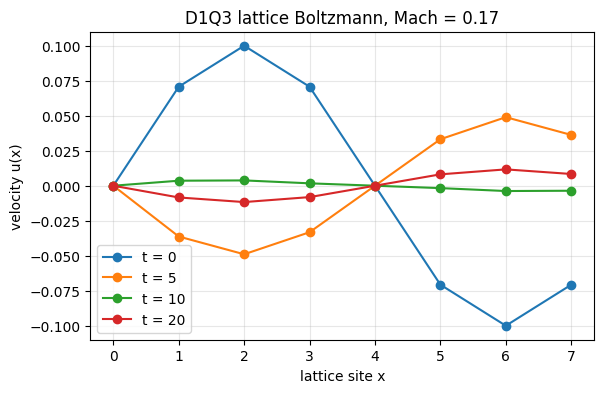

In [13]:
U0, T_lat = 0.1, 20
f0 = equilibrium(np.ones(n_lat), U0 * np.sin(2 * np.pi * x_lat / n_lat))
f = f0.copy()
for step in range(T_lat + 1):
    if step in (0, 5, 10, 20):
        plt.plot(x_lat, Jm @ f / (Rho @ f), "o-", label=f"t = {step}")
    f = lbm_step(f, S, C1, C2)
plt.xlabel("lattice site x"); plt.ylabel("velocity u(x)")
plt.title(f"D1Q3 lattice Boltzmann, Mach = {U0 / np.sqrt(cs2):.2f}"); plt.legend(); plt.show()

**Carleman for the time-step map.** For $y_k = f^{\otimes k}$, $\;y_k' = S^{\otimes k}\big(C_1 f + C_2 f^{\otimes 2}\big)^{\otimes k}$. Each term with $m$ factors $C_2$ maps $y_{k+m}$ into $y_k'$. Keeping $y_1,\dots,y_N$ gives one linear map, applied $T$ times; its dimension is $3n + (3n)^2 + \dots + (3n)^N$, stored as a sparse matrix.

In [14]:
skron_all = lambda ms: reduce(lambda p, q: sp.kron(p, q, format="csr"), ms)


def carleman_lbm(S, C1, C2, N):
    D = S.shape[0]
    blocks = [[None] * N for _ in range(N)]
    for k in range(1, N + 1):
        Sk = skron_all([S] * k)
        for choice in product((0, 1), repeat=k):              # 0 -> C1 factor, 1 -> C2 factor
            j = k + sum(choice)
            if j <= N:
                term = Sk @ skron_all([C2 if ch else C1 for ch in choice])
                blocks[k - 1][j - 1] = term if blocks[k - 1][j - 1] is None else blocks[k - 1][j - 1] + term
    for k in range(N):
        for j in range(N):
            if blocks[k][j] is None:
                blocks[k][j] = sp.csr_matrix((D ** (k + 1), D ** (j + 1)))
    return sp.bmat(blocks, format="csr")


def carleman_error(n, omega, U0, T, N):
    S, C1, C2, Rho, Jm = lbm_operators(n, omega)
    f0 = equilibrium(np.ones(n), U0 * np.sin(2 * np.pi * np.arange(n) / n))
    f = f0.copy()
    for _ in range(T):
        f = lbm_step(f, S, C1, C2)
    A = carleman_lbm(S, C1, C2, N)
    y = np.concatenate([reduce(np.kron, [f0] * k) for k in range(1, N + 1)])
    for _ in range(T):
        y = A @ y
    J_ref, J_car = Jm @ f, Jm @ y[: Q_lat * n]
    return np.linalg.norm(J_car - J_ref) / np.linalg.norm(J_ref), A.shape[0]


print(f"Mach = {0.1 / np.sqrt(cs2):.2f}, omega = 1, 8 sites, 20 steps\n")
print(f"{'N':>2} {'dimension':>10} {'qubits':>7} {'rel. momentum error':>21}")
for N in (1, 2, 3):
    err, dim = carleman_error(n_lat, 1.0, 0.1, 20, N)
    print(f"{N:>2} {dim:>10} {int(np.ceil(np.log2(dim))):>7} {err:>21.1e}")

Mach = 0.17, omega = 1, 8 sites, 20 steps

 N  dimension  qubits   rel. momentum error
 1         24       5               9.1e-03
 2        600      10               4.4e-03


 3      14424      14               6.7e-05


**The Mach number controls the error.** Fix the viscosity ($\omega = 1$) and increase the flow speed.

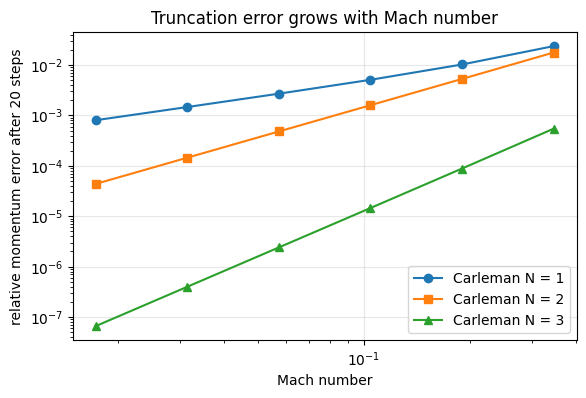

In [15]:
U0s = np.geomspace(0.01, 0.2, 6)
for N, mk in ((1, "o-"), (2, "s-"), (3, "^-")):
    e = [carleman_error(n_lat, 1.0, U, 20, N)[0] for U in U0s]
    plt.loglog(U0s / np.sqrt(cs2), e, mk, label=f"Carleman N = {N}")
plt.xlabel("Mach number"); plt.ylabel("relative momentum error after 20 steps")
plt.title("Truncation error grows with Mach number"); plt.legend(); plt.show()

**✏️ Exercise 5.** Write `viscosity(omega)` using $\nu = c_s^2(1/\omega - 1/2)$, and `reynolds(U0, n, omega)` $= U_0\, n / \nu$, the Reynolds number of the sine wave. They are used in the viscosity scan below.

In [16]:
def viscosity(omega):
    return cs2 * (1 / omega - 0.5)

def reynolds(U0, n, omega):
    return U0 * n / viscosity(omega)

In [17]:
check(viscosity(1.0) is not None and np.isclose(viscosity(1.0), 1 / 6), "viscosity(1) = 1/6 (fill in Exercise 5)")
check(reynolds(0.1, 8, 1.0) is not None and np.isclose(reynolds(0.1, 8, 1.0), 4.8), "Re = 4.8 for U0 = 0.1, n = 8, omega = 1")

print(f"\n{'omega':>6} {'nu':>7} {'Re':>6}   {'N=1':>8} {'N=2':>8} {'N=3':>8}")
for om in (0.5, 1.0, 1.5, 1.8):
    e = [carleman_error(n_lat, om, 0.1, 20, N)[0] for N in (1, 2, 3)]
    print(f"{om:>6.1f} {viscosity(om):>7.3f} {reynolds(0.1, n_lat, om):>6.1f}   " + " ".join(f"{v:>8.1e}" for v in e))

✓ viscosity(1) = 1/6 (fill in Exercise 5)
✓ Re = 4.8 for U0 = 0.1, n = 8, omega = 1

 omega      nu     Re        N=1      N=2      N=3
   0.5   0.500    1.6    1.0e-01  5.1e-03  2.3e-04
   1.0   0.167    4.8    9.1e-03  4.4e-03  6.7e-05
   1.5   0.056   14.4    2.7e-02  1.0e-02  1.1e-03
   1.8   0.019   43.2    2.0e-02  2.5e-02  7.9e-03


**Takeaways.**
- Low Mach number is the natural regime: at $\mathrm{Ma}\approx0.02$, third order reaches about $10^{-7}$.
- Viscosity still matters. At $\omega = 1.8$ ($\mathrm{Re}\approx 43$) the second order no longer improves on the first, and the third gains only a factor of about 3: over-relaxation amplifies truncation errors step by step. Lattice Boltzmann helps, but high Reynolds numbers remain open.
- The dimension grows like $(3n)^N$, but qubits only linearly in $N$: 14 qubits for $N = 3$ on 8 sites.

---
## Part 5: Running $e^{-iHt}$ on spin qubit hardware with SpinPulse

Parts 1–4 all end in the same primitive: Hamiltonian simulation, $e^{-iHt}$. Here we run it on a pulse-level model of a silicon spin qubit processor with **SpinPulse**, Quobly's open-source library (Apache 2.0). SpinPulse

1. transpiles a Qiskit circuit to the native gate set $\{R_x, R_y, R_z, R_{zz}\}$ on a linear chain of qubits,
2. turns every gate into control pulses (single-qubit drive pulses of a chosen shape, Gaussian here, and exchange pulses on the coupler for two-qubit gates),
3. simulates the pulses under classical 1/f ("pink") noise, characterized by the dephasing time $T_2^*$.

**Model.** A 3-spin Heisenberg chain in a transverse field, the exchange interaction that is native to spin qubits:

$$H = J\sum_{k}\big(X_kX_{k+1} + Y_kY_{k+1} + Z_kZ_{k+1}\big) + h\sum_k X_k, \qquad J = 1,\; h = 0.5,\; t = 1 .$$

On hardware, $e^{-iHt}$ is approximated by $r$ first-order Trotter steps, $\big(\prod_j e^{-iH_j t/r}\big)^r$.

**Installation:** `pip install spin-pulse` (also installs Qiskit and Qiskit Aer). This part takes about one minute to run.

Reference: Quobly, *The SpinPulse library for transpilation and noise-accurate simulation of spin qubit quantum computers*, arXiv:2601.10435 (2026).

In [18]:
import warnings
warnings.filterwarnings("ignore")
try:
    import qiskit as qi
    from qiskit.quantum_info import Operator, average_gate_fidelity
    from spin_pulse import HardwareSpecs, Shape, PulseCircuit, ExperimentalEnvironment
    from spin_pulse.environment.noise import NoiseType
except ImportError as err:
    raise ImportError("Part 5 needs SpinPulse: run  pip install spin-pulse  and restart the kernel") from err

nq, J_ex, h_x, t_sim = 3, 1.0, 0.5, 1.0


def pauli_on(ops):
    # Qiskit ordering: qubit 0 is the rightmost tensor factor
    return kron_all([PAULIS[ops.get(q, "I")] for q in reversed(range(nq))])


spin_terms = ([(J_ex, pauli_on({k: P, k + 1: P})) for k in range(nq - 1) for P in "XYZ"]
              + [(h_x, pauli_on({k: "X"})) for k in range(nq)])
H_spin = sum(c * P for c, P in spin_terms)
U_exact = expm(-1j * t_sim * H_spin)
exact_circ = qi.QuantumCircuit(nq)
exact_circ.unitary(U_exact, range(nq))
print("Exact propagator ready:", U_exact.shape)

Exact propagator ready: (8, 8)


**✏️ Exercise 6.** Write the Trotter circuit in Qiskit. Each step applies, in this order, the three exchange terms of every bond $(k, k+1)$ and then the field on every qubit. Qiskit's rotation gates are $R_{XX}(\theta) = e^{-i\theta XX/2}$ and $R_X(\theta) = e^{-i\theta X/2}$, so $e^{-iJ\,dt\,XX}$ needs $\theta = 2J\,dt$. Use `qc.rxx`, `qc.ryy`, `qc.rzz` and `qc.rx`.

In [19]:
def trotter_circuit(r):
    dt = t_sim / r
    qc = qi.QuantumCircuit(nq)
    for _ in range(r):
        for k in range(nq - 1):
            qc.rxx(2 * J_ex * dt, k, k + 1)
            qc.ryy(2 * J_ex * dt, k, k + 1)
            qc.rzz(2 * J_ex * dt, k, k + 1)
        for k in range(nq):
            qc.rx(2 * h_x * dt, k)
    return qc

In [20]:
U_one_step = reduce(lambda acc, cP: expm(-1j * t_sim * cP[0] * cP[1]) @ acc, spin_terms, np.eye(2**nq))
check(np.allclose(Operator(trotter_circuit(1)).data, U_one_step), "one Trotter step matches the product of exponentials (fill in Exercise 6)")

rs = [1, 2, 4, 8, 12]
F_ideal = [average_gate_fidelity(Operator(trotter_circuit(r)), Operator(U_exact)) for r in rs]
print("\nIdeal Trotter fidelity with e^(-iHt):")
for r, F in zip(rs, F_ideal):
    print(f"  r = {r:>2}:  {F:.4f}")

✓ one Trotter step matches the product of exponentials (fill in Exercise 6)

Ideal Trotter fidelity with e^(-iHt):
  r =  1:  0.1488
  r =  2:  0.6821
  r =  4:  0.9273
  r =  8:  0.9825
  r = 12:  0.9923


**From gates to pulses.** `HardwareSpecs` describes the device: 3 qubits on a line, the maximal magnetic field `B_field`, the maximal energy difference between qubits `delta`, and the maximal exchange coupling `J_coupling` (all in the model's dimensionless units). `gate_transpile` maps the circuit to native gates; `PulseCircuit` turns it into a pulse schedule. Without noise, the pulse fidelity checks that the pulses implement the transpiled circuit.

  r   Rzz  1-qubit  depth  duration  pulse fidelity


  1    12       55     41      3382          1.0000


  2    24      104     80      6103          1.0000


  4    48      200    156      7302          0.9999


  8    96      392    308      9662          1.0000


 12   144      584    460     12158          0.9975


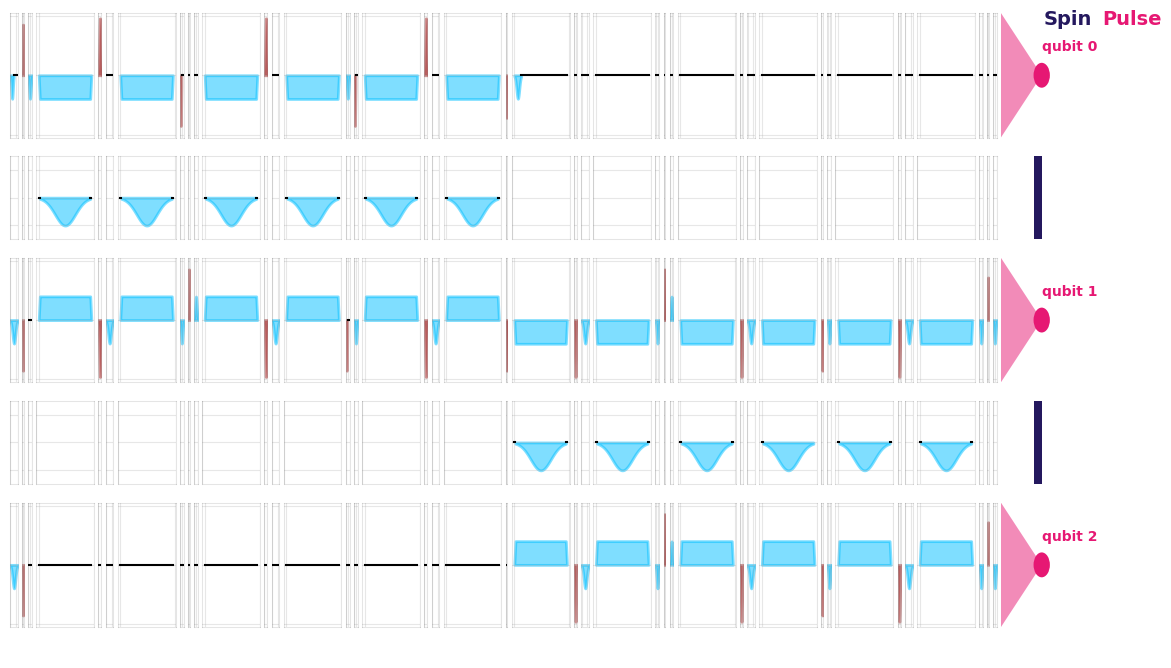

In [21]:
hw = HardwareSpecs(num_qubits=nq, B_field=0.5, delta=0.2, J_coupling=0.005,
                   rotation_shape=Shape.GAUSSIAN, ramp_duration=5, optim=3)

isa_circs = {r: hw.gate_transpile(trotter_circuit(r)) for r in rs}
print(f"{'r':>3} {'Rzz':>5} {'1-qubit':>8} {'depth':>6} {'duration':>9} {'pulse fidelity':>15}")
for r in rs:
    ops = isa_circs[r].count_ops()
    pc = PulseCircuit.from_circuit(isa_circs[r], hw)
    print(f"{r:>3} {ops.get('rzz', 0):>5} {sum(v for k, v in ops.items() if k != 'rzz'):>8} "
          f"{isa_circs[r].depth():>6} {pc.duration:>9} {pc.fidelity():>15.4f}")

PulseCircuit.from_circuit(isa_circs[1], hw).plot(hardware_specs=hw, label_gates=False)
plt.show()

**What to notice.** The gate count grows linearly with $r$, but the duration does not: an exchange pulse lasts in proportion to its rotation angle, and the total angle per bond is fixed by $J t$. Extra Trotter steps mainly add single-qubit pulses. The schedule above shows one Trotter step: pulses on the three qubit lines and, in between, the exchange pulses on the two couplers.

**Add 1/f noise.** Now the same pulse circuits run under pink noise with $T_2^* = 5000$ time units. The mean fidelity with the **exact** $e^{-iHt}$ combines Trotter error and hardware noise.

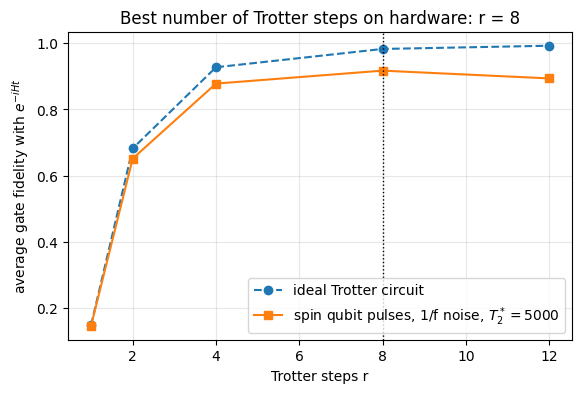

r =  1:  ideal 0.149   noisy hardware 0.147
r =  2:  ideal 0.682   noisy hardware 0.652
r =  4:  ideal 0.927   noisy hardware 0.878
r =  8:  ideal 0.983   noisy hardware 0.917
r = 12:  ideal 0.992   noisy hardware 0.894


In [22]:
env = ExperimentalEnvironment(hardware_specs=hw, noise_type=NoiseType.PINK, T2S=5000,
                              duration=2**17, segment_duration=2**17, seed=3)
F_noisy = []
for r in rs:
    pcn = PulseCircuit.from_circuit(isa_circs[r], hw, exp_env=env)
    F_noisy.append(pcn.mean_fidelity(env, circ_ref=exact_circ, progress_bar=False))

r_best = rs[int(np.argmax(F_noisy))]
plt.plot(rs, F_ideal, "o--", label="ideal Trotter circuit")
plt.plot(rs, F_noisy, "s-", label=r"spin qubit pulses, 1/f noise, $T_2^* = 5000$")
plt.axvline(r_best, color="k", lw=1, ls=":")
plt.xlabel("Trotter steps r"); plt.ylabel(r"average gate fidelity with $e^{-iHt}$")
plt.title(f"Best number of Trotter steps on hardware: r = {r_best}")
plt.legend(); plt.show()
for r, Fi, Fn in zip(rs, F_ideal, F_noisy):
    print(f"r = {r:>2}:  ideal {Fi:.3f}   noisy hardware {Fn:.3f}")

**Takeaways.**
- Without noise, more Trotter steps always help. With noise, every step adds pulses and time, so the fidelity peaks and then falls: here the best choice is around $r = 8$, at a fidelity just above 0.9, against 0.98 for the ideal circuit.
- Exchange pulses scale with the rotation angle, so on spin qubits finer Trotter steps cost less extra time than a fixed-duration two-qubit gate would.
- The optimum shifts with the noise: try `T2S=2000` or `T2S=20000` in the cell above. Dynamical decoupling (`DynamicalDecoupling.SPIN_ECHO` in `HardwareSpecs`) is a natural next experiment.
- Mean fidelities are averaged over 10–40 noise realizations, and the transpiler is not seeded, so expect small run-to-run variations.

---
## Part 6: Summary — every path ends in Hamiltonian simulation

| Step | Tool | What it buys | Main cost driver |
|---|---|---|---|
| Nonlinear → linear | Carleman, on the PDE or lattice Boltzmann form | A linear ODE or map | Order $N$; Mach and Reynolds numbers |
| Non-unitary → unitary | LCHS | A weighted sum of Hamiltonian simulations | Kernel tails, number of nodes |
| Matrix → circuit | LCU block encoding | Access to $A$ inside a unitary | Normalization $\alpha$ |
| Evolution → pulses | Trotter circuit on SpinPulse | $e^{-iHt}$ on a spin qubit model | Trotter steps vs noise; native gates |

**References**
- J.-P. Liu et al., *PNAS* 118, e2026805118 (2021) — Carleman for dissipative nonlinear ODEs
- D. An, J.-P. Liu, L. Lin, *PRL* 131, 150603 (2023) — LCHS
- A. Gilyén, Y. Su, G. H. Low, N. Wiebe, *STOC 2019*, 193–204 — block encoding and QSVT
- R. Itani, S. Succi, *Fluids* 7, 24 (2022) — Carleman linearization of lattice Boltzmann
- C. Sanavio, S. Succi, *AVS Quantum Sci.* 6, 023802 (2024) — lattice Boltzmann–Carleman circuits
- Quobly, SpinPulse, arXiv:2601.10435 (2026) — pulse-level simulation of spin qubit processors